<a href="https://colab.research.google.com/github/ikwak2/4Dgradcam/blob/main/DLaudio/1_STFT_Melspec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## STFT, Melspectrogram 피쳐 실습

코드는 [링크](https://haythamfayek.com/2016/04/21/speech-processing-for-machine-learning.html) 참고. 실습을 위한 데이터는 [여기](https://www.voiptroubleshooter.com/open_speech/american.html)서 첫 번째 파일 사용.

In [ ]:
!wget https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav

--2025-07-10 06:37:26--  https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav
Resolving www.voiptroubleshooter.com (www.voiptroubleshooter.com)... 162.241.218.124
Connecting to www.voiptroubleshooter.com (www.voiptroubleshooter.com)|162.241.218.124|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 538014 (525K) [audio/x-wav]
Saving to: ‘OSR_us_000_0010_8k.wav.1’

OSR_us_000_0010_8k. 100%[===================>] 525.40K   508KB/s    in 1.0s    

2025-07-10 06:37:28 (508 KB/s) - ‘OSR_us_000_0010_8k.wav.1’ saved [538014/538014]



In [ ]:
import numpy
import scipy.io.wavfile
from scipy.fftpack import dct

sample_rate, signal = scipy.io.wavfile.read('OSR_us_000_0010_8k.wav')  # File assumed to be in the same directory
signal = signal[0:int(3.5 * sample_rate)]  # Keep the first 3.5 seconds


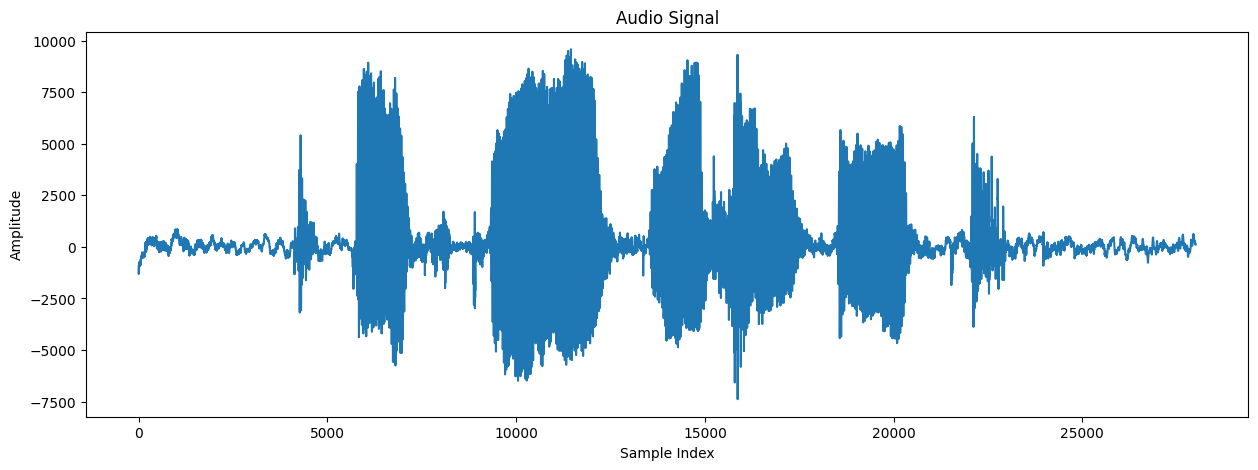

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(signal)
plt.title('Audio Signal')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
pre_emphasis = 0.97
emphasized_signal = numpy.append(signal[0], signal[1:] - pre_emphasis * signal[:-1])

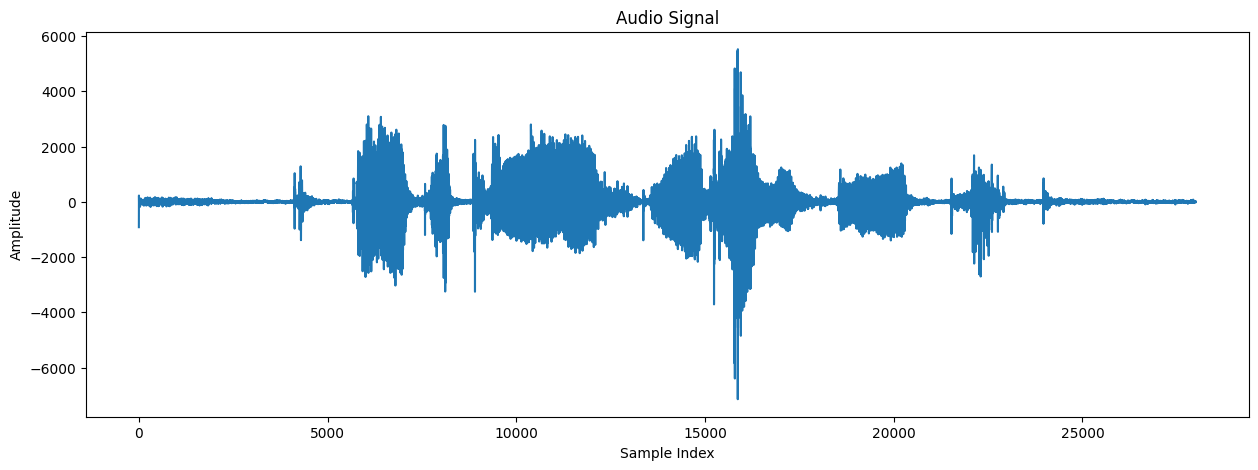

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(emphasized_signal)
plt.title('Audio Signal')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
from IPython.display import Audio, display

display(Audio(signal, rate=sample_rate))

display(Audio(emphasized_signal, rate=sample_rate))

In [ ]:
frame_size = 0.025 ; frame_stride = 0.01

In [ ]:
frame_length, frame_step = frame_size * sample_rate, frame_stride * sample_rate  # Convert from seconds to samples
signal_length = len(emphasized_signal)
frame_length = int(round(frame_length))
frame_step = int(round(frame_step))
num_frames = int(numpy.ceil(float(numpy.abs(signal_length - frame_length)) / frame_step))  # Make sure that we have at least 1 frame

pad_signal_length = num_frames * frame_step + frame_length
z = numpy.zeros((pad_signal_length - signal_length))
pad_signal = numpy.append(emphasized_signal, z) # Pad Signal to make sure that all frames have equal number of samples without truncating any samples from the original signal

indices = numpy.tile(numpy.arange(0, frame_length), (num_frames, 1)) + numpy.tile(numpy.arange(0, num_frames * frame_step, frame_step), (frame_length, 1)).T
frames = pad_signal[indices.astype(numpy.int32, copy=False)]

In [ ]:
frames.shape

(348, 200)

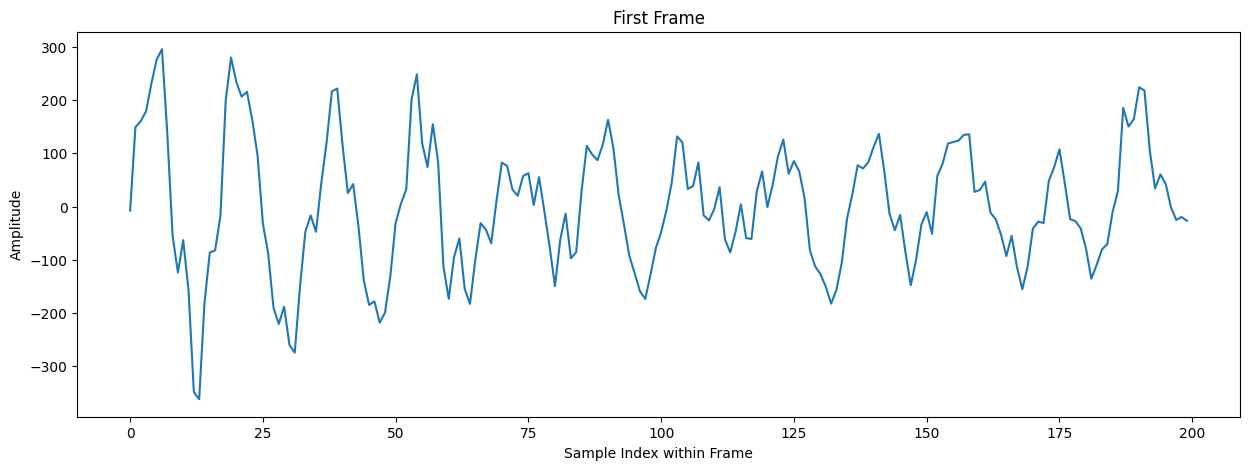

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
plt.plot(frames[90])
plt.title('First Frame')
plt.xlabel('Sample Index within Frame')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
plt.plot(frames[90])
plt.title('First Frame')
plt.xlabel('Sample Index within Frame')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
frames *= numpy.hamming(frame_length)

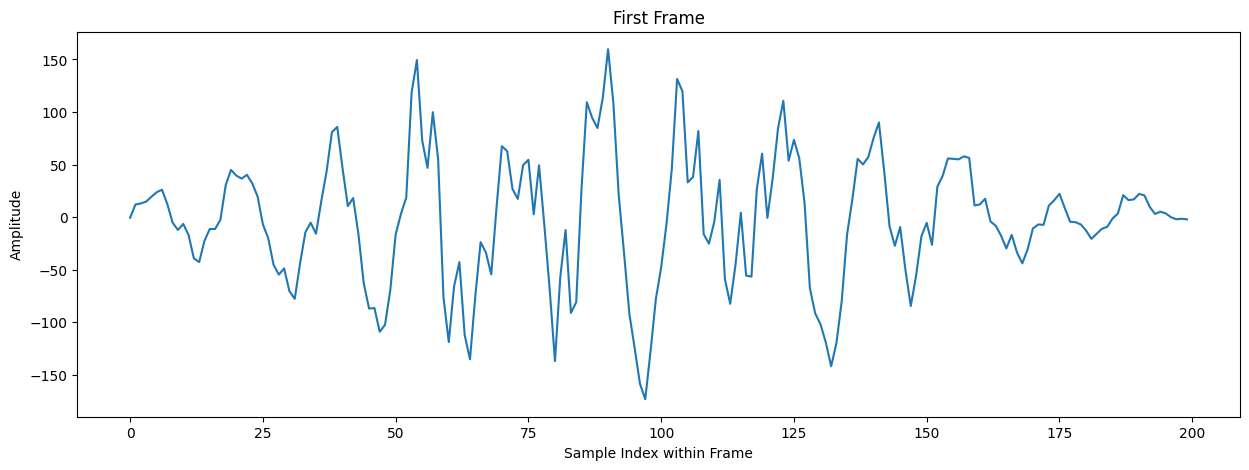

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
plt.plot(frames[90])
plt.title('First Frame')
plt.xlabel('Sample Index within Frame')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
NFFT = 512
mag_frames = numpy.absolute(numpy.fft.rfft(frames, NFFT))  # Magnitude of the FFT
pow_frames = ((1.0 / NFFT) * ((mag_frames) ** 2))  # Power Spectrum


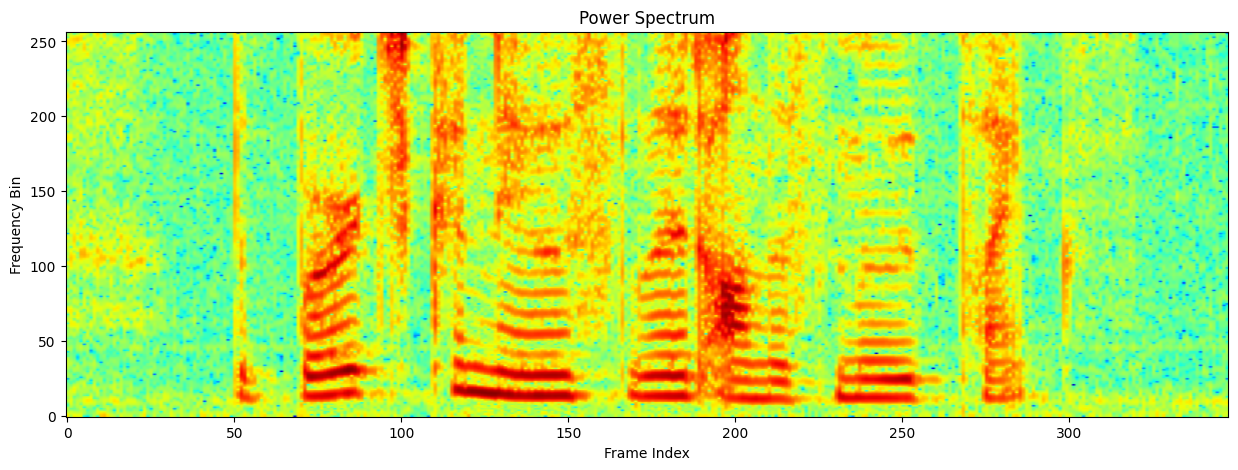

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
plt.imshow(np.log(pow_frames).T, aspect='auto', origin='lower', cmap='jet')
plt.title('Power Spectrum')
plt.xlabel('Frame Index')
plt.ylabel('Frequency Bin')
plt.show()

In [ ]:
nfilt = 40

In [ ]:
low_freq_mel = 0
high_freq_mel = (2595 * numpy.log10(1 + (sample_rate / 2) / 700))  # Convert Hz to Mel
mel_points = numpy.linspace(low_freq_mel, high_freq_mel, nfilt + 2)  # Equally spaced in Mel scale
hz_points = (700 * (10**(mel_points / 2595) - 1))  # Convert Mel to Hz
bin = numpy.floor((NFFT + 1) * hz_points / sample_rate)

fbank = numpy.zeros((nfilt, int(numpy.floor(NFFT / 2 + 1))))
for m in range(1, nfilt + 1):
    f_m_minus = int(bin[m - 1])   # left
    f_m = int(bin[m])             # center
    f_m_plus = int(bin[m + 1])    # right

    for k in range(f_m_minus, f_m):
        fbank[m - 1, k] = (k - bin[m - 1]) / (bin[m] - bin[m - 1])
    for k in range(f_m, f_m_plus):
        fbank[m - 1, k] = (bin[m + 1] - k) / (bin[m + 1] - bin[m])
filter_banks = numpy.dot(pow_frames, fbank.T)
filter_banks = numpy.where(filter_banks == 0, numpy.finfo(float).eps, filter_banks)  # Numerical Stability
filter_banks = 20 * numpy.log10(filter_banks)  # dB

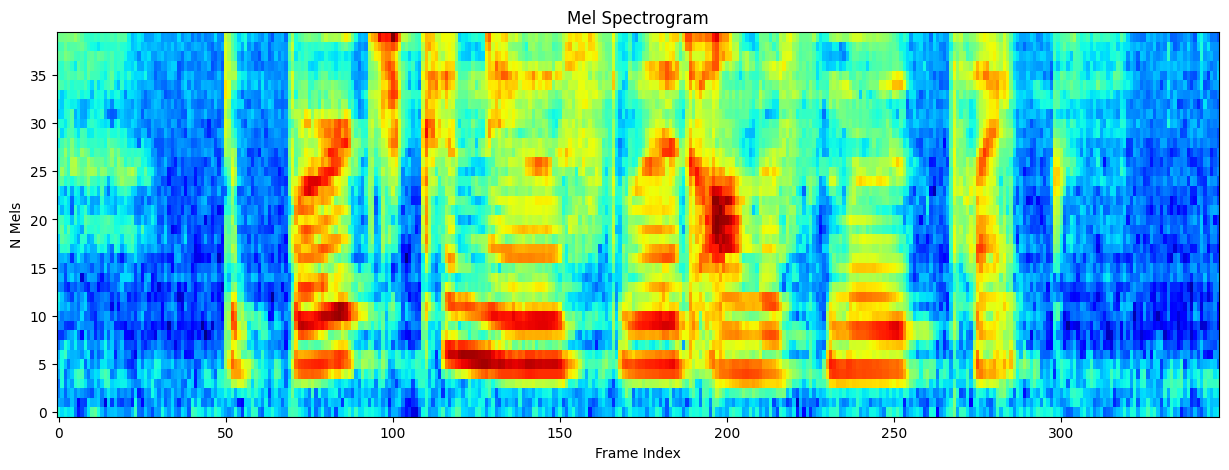

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
plt.imshow(filter_banks.T, aspect='auto', origin='lower', cmap='jet')
plt.title('Mel Spectrogram')
plt.xlabel('Frame Index')
plt.ylabel('N Mels')
plt.show()

## Using Librosa to take Mel-spectrogram feature

In [ ]:
import librosa

In [ ]:
y, sr = librosa.load("OSR_us_000_0010_8k.wav", sr=None)  # load an audio file in mono

In [ ]:
y

array([-0.02804565, -0.0401001 , -0.03201294, ..., -0.0100708 ,
       -0.00976562, -0.00915527], dtype=float32)

아까는 정수형인데, 왜 이번에는 소수점 형태?

librosa는 기본적으로 소수점 형태로 읽음. 왜 그렇고, 어떻게 바꿔야 하는지?

In [ ]:
sr

8000

In [ ]:
signal

array([ -919, -1314, -1049, ...,   148,   136,   120], dtype=int16)

In [ ]:
y * 32768

array([ -919., -1314., -1049., ...,  -330.,  -320.,  -300.], dtype=float32)

이유: 16bit Quantization 을 많이 씀.. 그럼 -32768 ~ 32768 정도의 정수로 음성신호가 표현됨. 때때로 32768로 나눠서 -1 ~ 1 사이로 표준화 해서 표현하기도 함. 그래서 float 형태로 읽어진 경우 32768 을 곱하면 정수형으로 복원됨. 대체로 16bit 많이 쓰는데 24bit 도 가끔 있으니 주의가 필요.

In [ ]:
2**16

65536

In [ ]:
mel_spec_librosa = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=512, hop_length=160,
                                                 n_mels=64, fmin=0, fmax=sr/2, power=2.0)
mel_spec_db_librosa = librosa.power_to_db(mel_spec_librosa, ref=np.max)

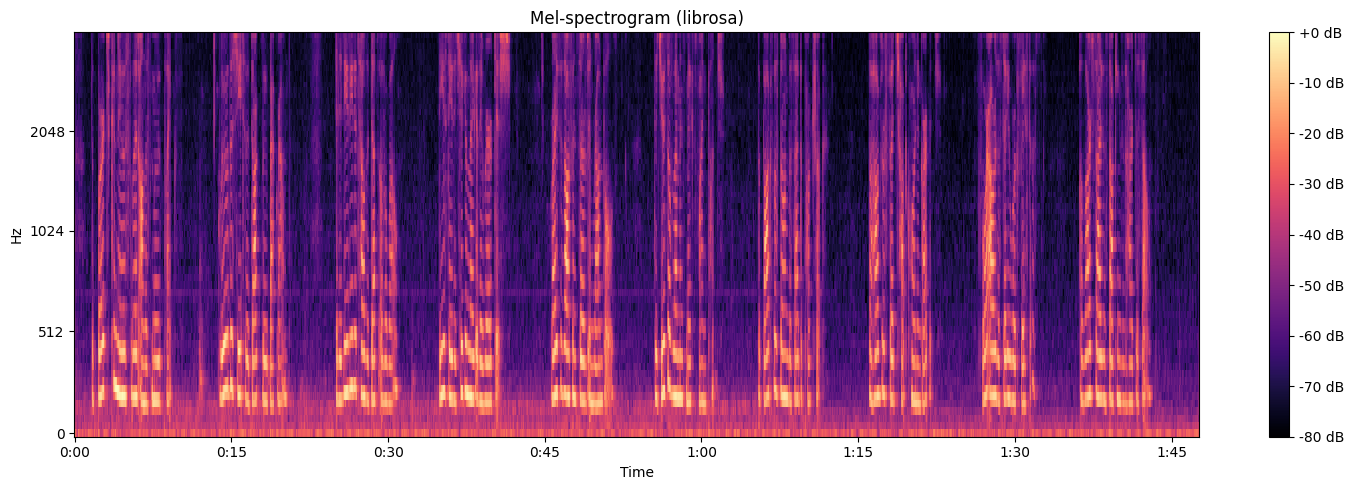

In [ ]:

import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
librosa.display.specshow(mel_spec_db_librosa, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-spectrogram (librosa)')
plt.tight_layout()
plt.show()

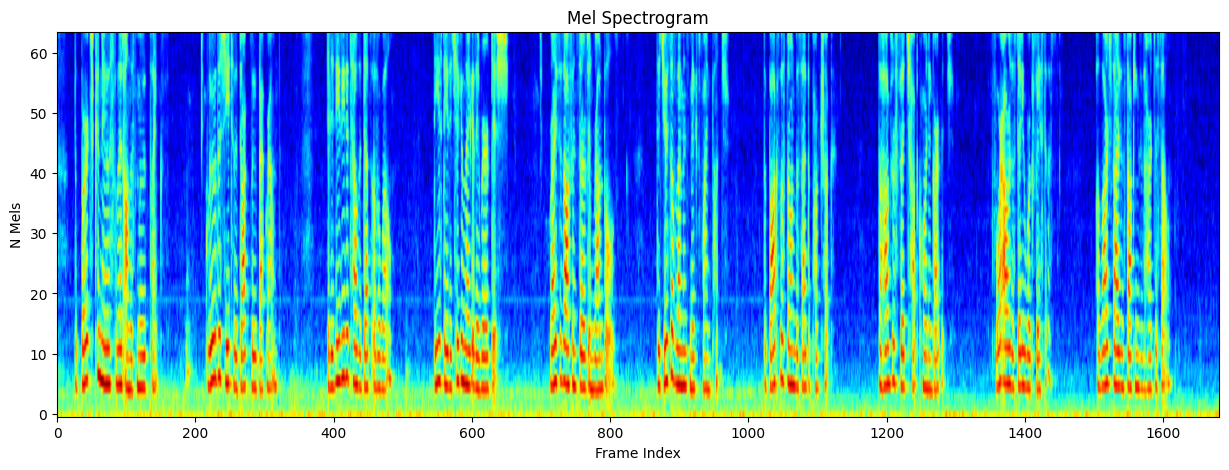

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
plt.imshow(mel_spec_db_librosa, aspect='auto', origin='lower', cmap='jet')
plt.title('Mel Spectrogram')
plt.xlabel('Frame Index')
plt.ylabel('N Mels')
plt.show()

## Using Pytorch to take Mel-spectrogram feature

For deep learning projects, you may use TorchAudio (the audio library in PyTorch) to integrate feature extraction into your pipeline (so it can run on GPU, be part of your Dataset preprocessing, etc.). TorchAudio provides transforms for spectrograms and mel-spectrograms. For example:

In [ ]:
import torch
import torchaudio
from torchaudio.transforms import MelSpectrogram

wave_tensor = torch.tensor(y).unsqueeze(0)  # convert our NumPy waveform to a PyTorch tensor and add batch dimension
mel_transform = MelSpectrogram(sample_rate=sr, n_fft=512, hop_length=160,
                               n_mels=64, f_min=0.0, f_max=sr/2,
                               window_fn=torch.hann_window, power=2.0)
mel_spec_torch = mel_transform(wave_tensor)  # shape: [1, 64, time_frames]
mel_spec_torch_db = torchaudio.functional.amplitude_to_DB(mel_spec_torch, multiplier=10.0, amin=1e-10, db_multiplier=0)  # convert to dB

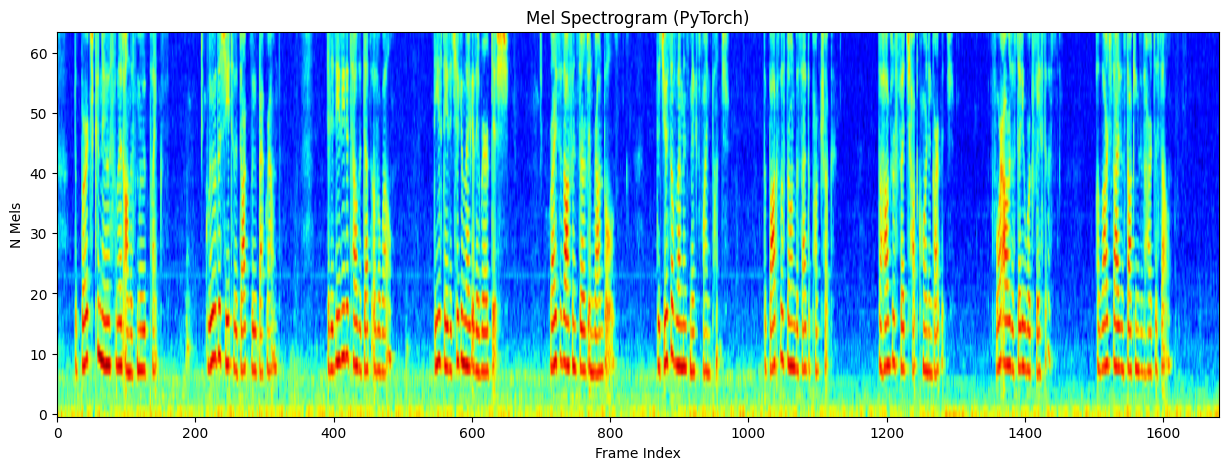

In [ ]:

import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
plt.imshow(mel_spec_torch_db.squeeze(0).numpy(), aspect='auto', origin='lower', cmap='jet')
plt.title('Mel Spectrogram (PyTorch)')
plt.xlabel('Frame Index')
plt.ylabel('N Mels')
plt.show()

A few notes:
- We used MelSpectrogram transform which under the hood does Spectrogram -> MelScale. We specified similar parameters (note: PyTorch by default uses Hann window if not specified; here we explicitly passed one).
- The output is a PyTorch tensor. If running on a GPU, you could move wave_tensor to CUDA and the transform will run on GPU as well, which can be faster for large batches.
- We then converted amplitude to dB using amplitude_to_DB (in this case, since we have power spectrogram, we should actually set multiplier=10 to do 10*log10). This function is analogous to librosa’s power_to_db.
- The resulting mel_spec_torch_db can be converted to numpy for plotting or fed directly into a PyTorch model.